# Warming Cities — exploratory analysis

How much have eleven major cities warmed, how fast, and what is happening to their air?

This notebook is the statistical core of the project. It reads the cleaned annual series from
`clean.py` and runs the numbers in `analysis.py` (a tested module — the same code feeds the
website's JSON export, so what you see here is what the site shows).

**Data**
- Temperature: NOAA GHCN-Monthly v4, quality-controlled and homogenized (`qcf`), one station per
  city chosen for the most complete 1961–1990 baseline among current stations within 50 km.
- Air quality: OpenAQ v3 monthly PM2.5 aggregates from reference-grade monitors within 25 km.

**Rebuild:** `python download_temperature.py`, `python download_air_quality.py`,
`python clean.py`, then run this notebook (`pip install -r requirements-notebook.txt`).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ETL = Path.cwd().parent
sys.path.insert(0, str(ETL))
import analysis  # noqa: E402

temp, aq = analysis.load_processed(ETL / "data" / "processed")
temp = analysis.add_anomalies(temp)
temp = analysis.add_rolling_mean(temp, "anomaly_c")
quality = json.loads((ETL / "data" / "processed" / "quality_report.json").read_text())

NAMES = {
    "lahore": "Lahore", "beijing": "Beijing", "sao_paulo": "São Paulo",
    "addis_ababa": "Addis Ababa", "new_york": "New York", "delhi": "Delhi",
    "ho_chi_minh_city": "Ho Chi Minh City", "jakarta": "Jakarta", "london": "London",
    "sydney": "Sydney", "santiago": "Santiago",
}
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
WARM, COOL, PM_HUE = "#e34948", "#2a78d6", "#eb6834"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif",
})
pd.set_option("display.precision", 2)

## 1. What data survived cleaning

Temperature records are long; PM2.5 records are short — OpenAQ coverage only starts around
2016 and is patchy in places. `baseline_years` is how many of the 30 reference years
(1961–1990) each station has; anomalies are measured against that period.

In [2]:
coverage = pd.DataFrame({
    NAMES[c]: {
        "temp years": f"{q['temperature']['first_year']}–{q['temperature']['last_year']}",
        "baseline years": f"{q['temperature']['baseline_years']}/30",
        "PM2.5 years": f"{q['air_quality']['first_year']}–{q['air_quality']['last_year']}"
        f" ({q['air_quality']['n_years']})",
        "max PM2.5 stations": q["air_quality"]["max_locations"],
        "spike months dropped": q["air_quality"]["spike_months"],
    }
    for c, q in quality.items()
}).T
coverage

,temp years,baseline years,PM2.5 years,max PM2.5 stations,spike months dropped
Lahore,1876–2025,25/30,2020–2024 (5),1,0
Beijing,1841–2025,28/30,2016–2024 (9),14,6
São Paulo,1887–2025,27/30,2021–2024 (4),15,0
Addis Ababa,1902–2025,27/30,2017–2025 (9),3,1
New York,1846–2025,30/30,2016–2026 (11),15,11
Delhi,1931–2025,30/30,2016–2026 (11),40,25
Ho Chi Minh City,1954–2024,26/30,2016–2021 (6),1,17
Jakarta,1866–2025,14/30,2016–2025 (10),5,12
London,1948–2025,30/30,2016–2026 (11),82,19
Sydney,1859–2025,30/30,2018–2022 (4),6,1


## 2. Temperature anomalies

Each bar is one year's mean temperature minus the city's own 1961–1990 average (red = warmer,
blue = cooler); the black line is a centred 10-year rolling mean. All panels share one y-axis,
so the size of the warming is directly comparable between cities. Shown from 1900.

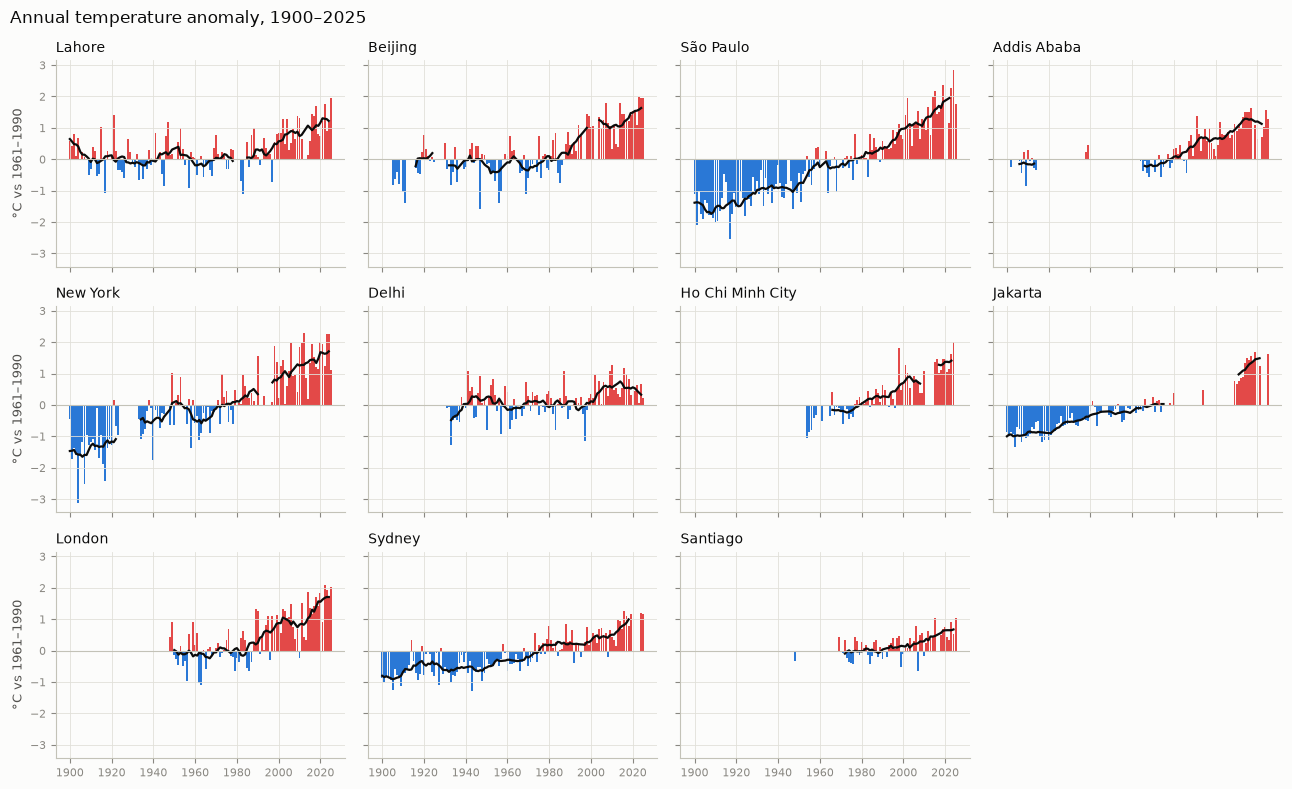

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharex=True, sharey=True)
for ax, city in zip(axes.flat, NAMES, strict=False):
    d = temp[(temp["city"] == city) & (temp["year"] >= 1900)]
    colors = [WARM if v > 0 else COOL for v in d["anomaly_c"]]
    ax.bar(d["year"], d["anomaly_c"], width=0.9, color=colors, linewidth=0)
    ax.plot(d["year"], d["anomaly_c_rolling"], color=INK, linewidth=1.6)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.set_title(NAMES[city], loc="left")
axes.flat[-1].axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("°C vs 1961–1990")
fig.suptitle("Annual temperature anomaly, 1900–2025", x=0.01, ha="left", color=INK)
fig.tight_layout()

## 3. How fast is each city warming?

OLS trend of annual mean temperature since **1970** — every city's fit starts from the same
year, because station records begin anywhere from 1841 to 1954 and full-record slopes would not
be comparable. Whiskers are 95% confidence intervals.

,per_decade_c,ci95_low_c,ci95_high_c,p_value,n_years
city,,,,,
Delhi,0.12,0.05,0.19,1.27e-03,56
Santiago,0.15,0.09,0.21,3.21e-06,51
Sydney,0.20,0.14,0.26,1.55e-08,52
Lahore,0.27,0.18,0.35,1.28e-07,50
Addis Ababa,0.29,0.23,0.34,1.06e-13,54
Jakarta,0.29,0.24,0.34,1.70e-10,23
Ho Chi Minh City,0.34,0.28,0.40,7.01e-15,49
London,0.34,0.26,0.43,8.85e-11,56
New York,0.35,0.25,0.44,1.41e-09,52


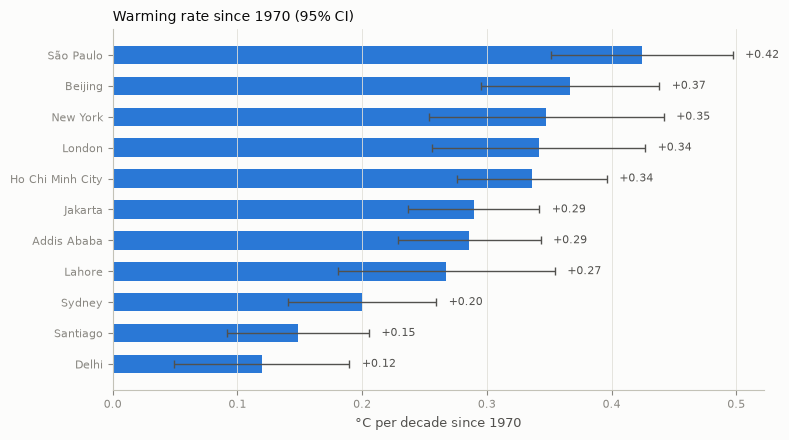

In [4]:
trends = analysis.temperature_trends(temp).assign(city=lambda d: d["city"].map(NAMES))
trends = trends.sort_values("per_decade_c")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(trends["city"], trends["per_decade_c"], color=COOL, height=0.6)
ax.errorbar(
    trends["per_decade_c"], trends["city"],
    xerr=[trends["per_decade_c"] - trends["ci95_low_c"],
          trends["ci95_high_c"] - trends["per_decade_c"]],
    fmt="none", ecolor=INK_2, elinewidth=1, capsize=3,
)
for y, v in enumerate(trends["per_decade_c"]):
    ax.text(trends["ci95_high_c"].iloc[y] + 0.01, y, f"{v:+.2f}", va="center", fontsize=8,
            color=INK_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("°C per decade since 1970")
ax.set_title("Warming rate since 1970 (95% CI)", loc="left")
fig.tight_layout()

trends.set_index("city")[["per_decade_c", "ci95_low_c", "ci95_high_c", "p_value", "n_years"]]

**Findings — temperature**

- **Every city has warmed**, and every 95% interval excludes zero. Rates run from about
  +0.1 °C/decade (Delhi) to about +0.4 °C/decade (São Paulo), with most cities between
  +0.3 and +0.4 — in line with the global land warming rate since 1970.
- Measured against 1961–1990, the last decade (2016–2025) averages roughly **+0.5 to +1.9 °C**
  depending on the city (see `analysis_summary.json`).
- **Delhi warms slowest.** That is a real feature of the Safdarjung record, not a cleaning
  artifact; a possible contributor is aerosol "dimming" over northern India, where heavy
  particulate pollution reflects sunlight and offsets part of the greenhouse warming. We report
  the number as measured and don't adjust it.
- **Santiago** also warms slowly (+0.15 °C/decade); coastal-influenced central Chile is a
  known region of muted warming. Its baseline has 21/30 years.
- **Jakarta's** record is the weakest: 14 of 30 baseline years, and almost nothing between 1985
  and 2008 (one year, 1994). The record resumes in 2009 about 1.5 °C warmer than where it left
  off, so part of that step may be a station or instrument change that the 14-year gap hides
  from GHCN's homogenization. Treat Jakarta's anomalies and trend as the least certain of the
  eleven; no nearby current station has a better record.

## 4. PM2.5 — what's happening to the air

Annual season-adjusted PM2.5 per city. **y-axes differ per panel** — the cities span more than
an order of magnitude (Sydney ~7 µg/m³, Lahore ~120), so a shared axis would flatten every
clean city to a line. The dashed line is the WHO 2021 annual guideline (5 µg/m³).

,first_year,last_year,n_years,mean_pm25,pct_per_year,p_value,sufficient
city,,,,,,,
Addis Ababa,2017,2025,9,28.38,-3.60,1.39e-02,True
Beijing,2016,2024,9,45.16,-6.21,1.25e-02,True
Delhi,2016,2026,11,106.03,-2.67,1.70e-03,True
Ho Chi Minh City,2016,2021,6,29.34,-5.32,7.95e-02,True
Jakarta,2016,2025,10,38.78,-2.06,2.49e-01,True
Lahore,2020,2024,5,121.95,3.91,1.82e-01,True
London,2016,2026,11,10.68,-3.61,5.53e-03,True
New York,2016,2026,11,8.08,-1.15,2.97e-01,True
Santiago,2016,2026,10,29.06,1.91,1.21e-01,True


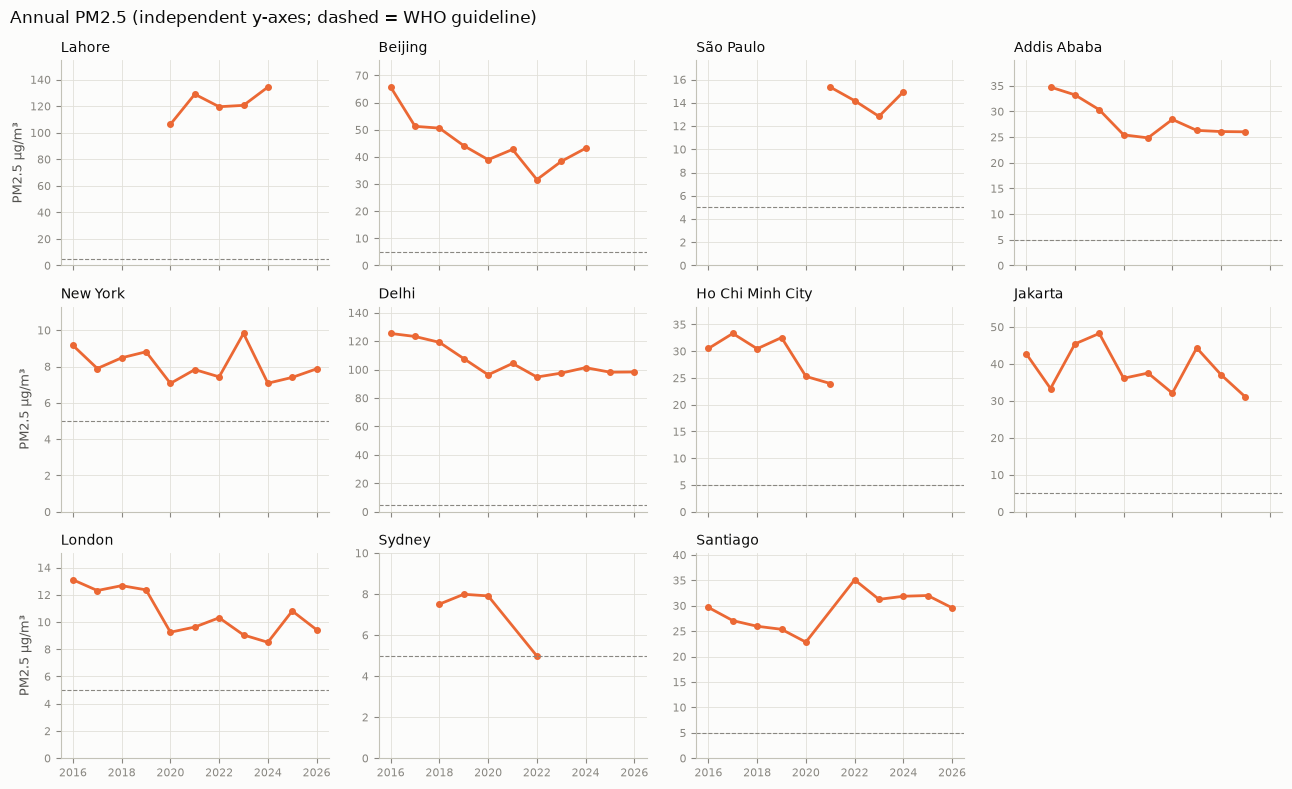

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharex=True)
for ax, city in zip(axes.flat, NAMES, strict=False):
    d = aq[aq["city"] == city]
    ax.plot(d["year"], d["pm25"], color=PM_HUE, linewidth=2, marker="o", markersize=4)
    ax.axhline(5, color=MUTED, linewidth=0.8, linestyle="--")
    ax.set_ylim(0, max(d["pm25"].max() * 1.15, 10))
    ax.set_title(NAMES[city], loc="left")
axes.flat[-1].axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("PM2.5 µg/m³")
fig.suptitle("Annual PM2.5 (independent y-axes; dashed = WHO guideline)", x=0.01, ha="left",
             color=INK)
fig.tight_layout()

pm = analysis.pm25_trends(aq).assign(city=lambda d: d["city"].map(NAMES)).set_index("city")
pm[["first_year", "last_year", "n_years", "mean_pm25", "pct_per_year", "p_value", "sufficient"]]

**Findings — air quality**

- **Every city is above the WHO guideline** of 5 µg/m³ in every year we have; Lahore and Delhi
  average over 20× it.
- Where the record is long enough to say anything, **PM2.5 is mostly falling**: Beijing (about
  −6%/year), London, Addis Ababa and Delhi have statistically significant declines
  (p < 0.05). New York, Jakarta and Ho Chi Minh City trend down without significance.
- Lahore (single monitor, 2020–2024) and Santiago trend up, but neither is significant.
- **São Paulo and Sydney** have fewer than 5 usable years, so no trend is reported for them.

## 5. Temperature vs PM2.5 — and why not to over-read it

Pearson correlation between each city's annual temperature anomaly and annual PM2.5 over the
years both exist — raw (`r`) and **detrended** (`r_detrended`, each series' linear trend removed
first). The detrended one is the honest measure: two series that both just drift over the same
years correlate raw with no year-to-year link at all.

> **Correlation is not causation.** Long-term warming is driven by global greenhouse-gas
> concentrations; PM2.5 by local emissions (traffic, industry, crop burning) and weather. The two
> are largely independent mechanisms that happen to co-occur. With at most ~10 overlapping
> years per city, and nine cities tested, one "significant" result is roughly what chance alone
> produces.

,n_years,r,p_value,r_detrended,p_detrended
city,,,,,
Addis Ababa,7,0.42,3.42e-01,0.68,0.09
Beijing,9,-0.10,7.97e-01,0.72,0.03
Delhi,10,0.82,3.49e-03,0.72,0.02
Ho Chi Minh City,6,0.03,9.56e-01,-0.07,0.90
Jakarta,7,-0.07,8.81e-01,0.02,0.96
Lahore,5,0.35,5.58e-01,0.29,0.64
London,10,-0.35,3.29e-01,0.19,0.60
New York,10,0.11,7.52e-01,0.18,0.63
Santiago,7,-0.10,8.32e-01,-0.70,0.08


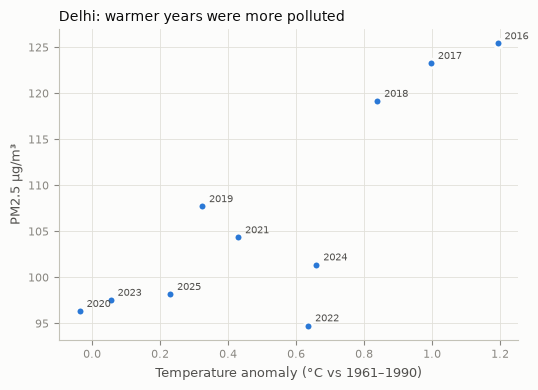

In [6]:
corr = analysis.temp_pm25_correlation(temp, aq).assign(city=lambda d: d["city"].map(NAMES))
display(corr.set_index("city"))

delhi = temp.merge(aq, on=["city", "year"]).query("city == 'delhi'")
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(delhi["anomaly_c"], delhi["pm25"], color=COOL, s=40, edgecolor="#fcfcfb",
           linewidth=2, zorder=3)
for _, r in delhi.iterrows():
    ax.annotate(int(r["year"]), (r["anomaly_c"], r["pm25"]), textcoords="offset points",
                xytext=(5, 3), fontsize=7, color=INK_2)
ax.set_xlabel("Temperature anomaly (°C vs 1961–1990)")
ax.set_ylabel("PM2.5 µg/m³")
ax.set_title("Delhi: warmer years were more polluted", loc="left")
fig.tight_layout()

**Reading the results.** Two cities show a year-to-year link that survives detrending:
**Delhi** (raw r ≈ 0.82, detrended ≈ 0.72, p ≈ 0.02) and **Beijing** (raw ≈ −0.10 — its
falling PM2.5 trend hides it — detrended ≈ 0.72, p ≈ 0.03). In both, a warmer-than-usual year
tended to be a more polluted one. The likely shared driver is weather: hot, dry, stagnant
conditions trap particulates (and in Delhi, crop-burning seasons vary year to year). That is
weather moving both series, not warming causing pollution or the reverse.

Two caveats keep this modest: each city has only 7–10 overlapping years, and with nine cities
tested at p < 0.05, about one "significant" result is expected by chance alone. The other cities
show no meaningful link. The site presents temperature and air quality side by side, never as
cause and effect.

## 6. Limitations

- **Single stations.** Each city's temperature comes from one station, which can carry local
  effects (urban heat island, airport siting). GHCN's homogenization corrects station moves and
  instrument changes, not urbanization.
- **Short, uneven PM2.5 records** (2016 at the earliest; São Paulo from 2021, Sydney ending
  2022, Ho Chi Minh City's monitor ending 2021 after a period of faulty readings). Every city
  is missing ~2 months of 2023 because of an upstream OpenAQ gap.
- **Changing monitor networks.** London grows from a few PM2.5 monitors to ~80; the city mean
  can shift as stations come and go.
- **Linear trends** summarize the rate; they aren't forecasts. No projection is made here.

The derived numbers are written below for Phase 3's export.

In [7]:
summary = analysis.summarize(*analysis.load_processed(ETL / "data" / "processed"))
out = ETL / "data" / "processed" / "analysis_summary.json"
out.write_text(json.dumps(summary, indent=2))
print(f"wrote {out.name} for {len(summary)} cities")

wrote analysis_summary.json for 11 cities
